In [ ]:
import pandas as pd 
import seaborn as sns

# Importing the Matplotlib library for basic plotting functionalities (as plt)
import matplotlib.pyplot as plt
import numpy as np
cohort = sns.load_dataset("penguins")

In [46]:
cash_req_df = pd.read_csv(r"C:\DSML Bootcamp\project\project-1-ironhack-payments-2-en\project_dataset\extract - cash request - data analyst.csv")

In [47]:
fees_df = pd.read_csv(r"C:\DSML Bootcamp\project\project-1-ironhack-payments-2-en\project_dataset\extract - fees - data analyst - .csv")

In [48]:
cash_req_df.head()

,id,amount,status,created_at,updated_at,user_id,moderated_at,deleted_account_id,reimbursement_date,cash_request_received_date,money_back_date,transfer_type,send_at,recovery_status,reco_creation,reco_last_update
0,5,100.0,rejected,2019-12-10 19:05:21.596873+00,2019-12-11 16:47:42.40783+00,804.0,2019-12-11 16:47:42.405646+00,NaN,2020-01-09 19:05:21.596363+00,NaN,NaN,regular,NaN,NaN,NaN,NaN
1,70,100.0,rejected,2019-12-10 19:50:12.34778+00,2019-12-11 14:24:22.900054+00,231.0,2019-12-11 14:24:22.897988+00,NaN,2020-01-09 19:50:12.34778+00,NaN,NaN,regular,NaN,NaN,NaN,NaN
2,7,100.0,rejected,2019-12-10 19:13:35.82546+00,2019-12-11 09:46:59.779773+00,191.0,2019-12-11 09:46:59.777728+00,NaN,2020-01-09 19:13:35.825041+00,NaN,NaN,regular,NaN,NaN,NaN,NaN
3,10,99.0,rejected,2019-12-10 19:16:10.880172+00,2019-12-18 14:26:18.136163+00,761.0,2019-12-18 14:26:18.128407+00,NaN,2020-01-09 19:16:10.879606+00,NaN,NaN,regular,NaN,NaN,NaN,NaN
4,1594,100.0,rejected,2020-05-06 09:59:38.877376+00,2020-05-07 09:21:55.34008+00,7686.0,2020-05-07 09:21:55.320193+00,NaN,2020-06-05 22:00:00+00,NaN,NaN,regular,NaN,NaN,NaN,NaN


In [49]:
fees_df.head()

,id,cash_request_id,type,status,category,total_amount,reason,created_at,updated_at,paid_at,from_date,to_date,charge_moment
0,6537,14941.0,instant_payment,rejected,NaN,5.0,Instant Payment Cash Request 14941,2020-09-07 10:47:27.42315+00,2020-10-13 14:25:09.396112+00,2020-12-17 14:50:07.47011+00,NaN,NaN,after
1,6961,11714.0,incident,accepted,rejected_direct_debit,5.0,rejected direct debit,2020-09-09 20:51:17.998653+00,2020-10-13 14:25:15.537063+00,2020-12-08 17:13:10.45908+00,NaN,NaN,after
2,16296,23371.0,instant_payment,accepted,NaN,5.0,Instant Payment Cash Request 23371,2020-10-23 10:10:58.352972+00,2020-10-23 10:10:58.352994+00,2020-11-04 19:34:37.43291+00,NaN,NaN,after
3,20775,26772.0,instant_payment,accepted,NaN,5.0,Instant Payment Cash Request 26772,2020-10-31 15:46:53.643958+00,2020-10-31 15:46:53.643982+00,2020-11-19 05:09:22.500223+00,NaN,NaN,after
4,11242,19350.0,instant_payment,accepted,NaN,5.0,Instant Payment Cash Request 19350,2020-10-06 08:20:17.170432+00,2020-10-13 14:25:03.267983+00,2020-11-02 14:45:20.355598+00,NaN,NaN,after


In [50]:
#Merged data frame by "id"-chash file
#left= fees = x
#right= cash = y
fees_with_cash_requests = fees_df.merge(cash_req_df, left_on='cash_request_id', right_on='id', how='left')

In [51]:
#"fees_with_cash_requests" is the merged table1
fees_with_cash_requests.columns

Index(['id_x', 'cash_request_id', 'type', 'status_x', 'category',
       'total_amount', 'reason', 'created_at_x', 'updated_at_x', 'paid_at',
       'from_date', 'to_date', 'charge_moment', 'id_y', 'amount', 'status_y',
       'created_at_y', 'updated_at_y', 'user_id', 'moderated_at',
       'deleted_account_id', 'reimbursement_date',
       'cash_request_received_date', 'money_back_date', 'transfer_type',
       'send_at', 'recovery_status', 'reco_creation', 'reco_last_update'],
      dtype='object')

In [52]:
#name of merged table1 "fees_with_cash_requests"
#"send_at" when people recieved the money* 
fees_with_cash_requests["send_at"].info()

<class 'pandas.core.series.Series'>
RangeIndex: 21061 entries, 0 to 21060
Series name: send_at
Non-Null Count  Dtype 
--------------  ----- 
17570 non-null  object
dtypes: object(1)
memory usage: 164.7+ KB


In [53]:
#cash_request_id is the Id of every request, they are unique*
fees_with_cash_requests["cash_request_id"].info()

<class 'pandas.core.series.Series'>
RangeIndex: 21061 entries, 0 to 21060
Series name: cash_request_id
Non-Null Count  Dtype  
--------------  -----  
21057 non-null  float64
dtypes: float64(1)
memory usage: 164.7 KB


In [54]:
#isnull in all merged table*
fees_with_cash_requests.isnull().sum()

id_x                              0
cash_request_id                   4
type                              0
status_x                          0
category                      18865
total_amount                      0
reason                            0
created_at_x                      0
updated_at_x                      0
paid_at                        5530
from_date                     13295
to_date                       13295
charge_moment                     0
id_y                              4
amount                            4
status_y                          4
created_at_y                      4
updated_at_y                      4
user_id                         910
moderated_at                   9777
deleted_account_id            20155
reimbursement_date                4
cash_request_received_date     1298
money_back_date                1360
transfer_type                     4
send_at                        3491
recovery_status               14167
reco_creation               

In [55]:
#there are duplicates bc in one cash request could be more than 1 fee*  
duplicates_in_fees = fees_df['cash_request_id'].duplicated().sum()

In [56]:
duplicates_in_fees

np.int64(8127)

In [57]:
#name of merged table1 "fees_with_cash_requests"
#Merged table "fees_with_cash_reques"
#right= cash = y = id_y (4 lines), check box13
#remuving id_y null values and we created a copy of this new DF 
# "~" ising this sign we are telling the funtion que copy only the true infomation what means take only the NO null values (Invierte True por False y viceversa).
#.isnull()= we look for nulles values using this, but we required the Non null and copy them thats the reason why we change this using "~"
#we can use this .notnull() and do the same operation
#when we remove the "id_y'" nulles values, we remueve all the rest of that rows! 
clean_fees_df = fees_with_cash_requests[~fees_with_cash_requests['id_y'].isnull()]#use_id as well
clean_fees_df = fees_with_cash_requests[~fees_with_cash_requests['user_id'].isnull()].copy()
clean_fees_df

,id_x,cash_request_id,type,status_x,category,total_amount,reason,created_at_x,updated_at_x,paid_at,...,moderated_at,deleted_account_id,reimbursement_date,cash_request_received_date,money_back_date,transfer_type,send_at,recovery_status,reco_creation,reco_last_update
0,6537,14941.0,instant_payment,rejected,NaN,5.0,Instant Payment Cash Request 14941,2020-09-07 10:47:27.42315+00,2020-10-13 14:25:09.396112+00,2020-12-17 14:50:07.47011+00,...,NaN,NaN,2020-10-01 22:00:00+00,NaN,2020-10-06 22:00:00+00,instant,2020-09-14 10:46:57.735172+00,pending,2020-10-11 22:52:52.274832+00,2020-12-20 22:40:42.556534+00
1,6961,11714.0,incident,accepted,rejected_direct_debit,5.0,rejected direct debit,2020-09-09 20:51:17.998653+00,2020-10-13 14:25:15.537063+00,2020-12-08 17:13:10.45908+00,...,2020-08-10 14:58:19.039748+00,NaN,2020-09-07 22:00:00+00,2020-08-12,2020-12-02 03:02:41.180953+00,instant,2020-08-17 13:15:54.290998+00,completed,2020-09-09 20:51:17.992852+00,2020-10-10 22:58:13.306027+00
2,16296,23371.0,instant_payment,accepted,NaN,5.0,Instant Payment Cash Request 23371,2020-10-23 10:10:58.352972+00,2020-10-23 10:10:58.352994+00,2020-11-04 19:34:37.43291+00,...,NaN,NaN,2020-11-04 22:00:00+00,2020-10-27,2020-11-04 19:34:37.399122+00,instant,2020-10-23 10:10:52.894637+00,NaN,NaN,NaN
3,20775,26772.0,instant_payment,accepted,NaN,5.0,Instant Payment Cash Request 26772,2020-10-31 15:46:53.643958+00,2020-10-31 15:46:53.643982+00,2020-11-19 05:09:22.500223+00,...,NaN,NaN,2020-11-11 23:51:00+00,2020-11-03,2020-11-17 23:00:00+00,instant,2020-10-31 15:46:46.846335+00,NaN,NaN,NaN
5,17029,24052.0,instant_payment,accepted,NaN,5.0,Instant Payment Cash Request 24052,2020-10-24 12:22:27.666102+00,2020-10-24 12:22:27.666124+00,2020-11-09 19:10:14.47407+00,...,NaN,NaN,2020-11-09 22:00:00+00,2020-10-25,2020-11-09 19:10:14.441234+00,instant,2020-10-24 12:22:12.220252+00,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21056,12372,20262.0,instant_payment,rejected,NaN,5.0,Instant Payment Cash Request 20262,2020-10-10 06:42:22.822743+00,2020-10-13 14:25:04.18049+00,2020-11-17 05:14:00.080854+00,...,NaN,NaN,2020-11-10 11:00:00+00,2020-10-13,2020-11-16 23:00:00+00,instant,2020-10-10 06:41:59.613815+00,pending,2020-11-21 22:21:53.12443+00,2020-11-21 22:21:57.85823+00
21057,20768,26764.0,instant_payment,rejected,NaN,5.0,Instant Payment Cash Request 26764,2020-10-31 15:24:18.680694+00,2020-10-31 15:24:18.680715+00,2020-12-16 07:10:54.697639+00,...,NaN,NaN,2020-11-10 23:51:00+00,2020-11-03,NaN,instant,2020-10-31 15:23:28.966185+00,pending,2020-11-21 22:50:26.679591+00,2020-12-19 22:30:03.346628+00
21058,18779,25331.0,instant_payment,rejected,NaN,5.0,Instant Payment Cash Request 25331,2020-10-27 17:28:51.749177+00,2020-10-27 17:28:51.7492+00,2020-11-18 04:35:42.915511+00,...,NaN,NaN,2020-11-10 23:51:00+00,2020-10-29,NaN,instant,2020-10-27 17:28:27.073945+00,pending,2020-11-22 22:15:47.957828+00,2020-11-22 22:15:51.383283+00
21059,16542,23628.0,instant_payment,rejected,NaN,5.0,Instant Payment Cash Request 23628,2020-10-23 16:27:52.047457+00,2020-10-23 16:27:52.047486+00,2020-12-18 05:18:01.465317+00,...,NaN,NaN,2020-11-15 11:00:00+00,2020-10-24,NaN,instant,2020-10-23 16:27:48.109023+00,pending,2020-11-25 22:43:52.728522+00,2020-12-23 22:42:25.1848+00


In [58]:
clean_fees_df["id_y"].info()

<class 'pandas.core.series.Series'>
Index: 20151 entries, 0 to 21060
Series name: id_y
Non-Null Count  Dtype  
--------------  -----  
20151 non-null  float64
dtypes: float64(1)
memory usage: 314.9 KB


In [59]:
#isnull in new clean DF 
clean_fees_df.isnull().sum()

id_x                              0
cash_request_id                   0
type                              0
status_x                          0
category                      18121
total_amount                      0
reason                            0
created_at_x                      0
updated_at_x                      0
paid_at                        5135
from_date                     12860
to_date                       12860
charge_moment                     0
id_y                              0
amount                            0
status_y                          0
created_at_y                      0
updated_at_y                      0
user_id                           0
moderated_at                   9568
deleted_account_id            20151
reimbursement_date                0
cash_request_received_date     1261
money_back_date                1351
transfer_type                     0
send_at                        3102
recovery_status               13686
reco_creation               

In [60]:
clean_fees_df["send_at"].isnull().sum()

np.int64(3102)

In [61]:
#here we are separating the date by moth 
# in column "send_at" we have this "2020-09-14 10:46:57.735172+00" using this funtion we only keep year and month "2020-09"
clean_fees_df["send_at"] = pd.to_datetime(clean_fees_df["send_at"], errors='coerce').dt.to_period('M')

C:\Users\Kaan\AppData\Local\Temp\ipykernel_5216\3734486115.py:3: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  clean_fees_df["send_at"] = pd.to_datetime(clean_fees_df["send_at"], errors='coerce').dt.to_period('M')


In [62]:
#this funtion is sortered the user_id by moth, will show the earlier month that someone request money  
df_groupby = clean_fees_df.groupby("user_id")["send_at"].min().reset_index()

In [63]:
df_groupby

,user_id,send_at
0,47.0,2020-10
1,52.0,2020-09
2,53.0,2020-10
3,72.0,2020-10
4,73.0,2020-09
...,...,...
8867,103421.0,2020-11
8868,103425.0,2020-11
8869,103437.0,2020-11
8870,103496.0,2020-11


In [64]:
#we are merging the table1 (firts merger clean_fees_df) with df_groupby what sort sortered the user_id by moth, will show the earlier month that someone request money  
# the key are "user_id", if the are coincident between "user_id" in both DF we funtion will add "send_at" to our clean_fees_df
final_df = clean_fees_df.merge(df_groupby[["user_id","send_at"]], on = "user_id", how = "left")
final_df

,id_x,cash_request_id,type,status_x,category,total_amount,reason,created_at_x,updated_at_x,paid_at,...,deleted_account_id,reimbursement_date,cash_request_received_date,money_back_date,transfer_type,send_at_x,recovery_status,reco_creation,reco_last_update,send_at_y
0,6537,14941.0,instant_payment,rejected,NaN,5.0,Instant Payment Cash Request 14941,2020-09-07 10:47:27.42315+00,2020-10-13 14:25:09.396112+00,2020-12-17 14:50:07.47011+00,...,NaN,2020-10-01 22:00:00+00,NaN,2020-10-06 22:00:00+00,instant,2020-09,pending,2020-10-11 22:52:52.274832+00,2020-12-20 22:40:42.556534+00,2020-09
1,6961,11714.0,incident,accepted,rejected_direct_debit,5.0,rejected direct debit,2020-09-09 20:51:17.998653+00,2020-10-13 14:25:15.537063+00,2020-12-08 17:13:10.45908+00,...,NaN,2020-09-07 22:00:00+00,2020-08-12,2020-12-02 03:02:41.180953+00,instant,2020-08,completed,2020-09-09 20:51:17.992852+00,2020-10-10 22:58:13.306027+00,2020-08
2,16296,23371.0,instant_payment,accepted,NaN,5.0,Instant Payment Cash Request 23371,2020-10-23 10:10:58.352972+00,2020-10-23 10:10:58.352994+00,2020-11-04 19:34:37.43291+00,...,NaN,2020-11-04 22:00:00+00,2020-10-27,2020-11-04 19:34:37.399122+00,instant,2020-10,NaN,NaN,NaN,2020-10
3,20775,26772.0,instant_payment,accepted,NaN,5.0,Instant Payment Cash Request 26772,2020-10-31 15:46:53.643958+00,2020-10-31 15:46:53.643982+00,2020-11-19 05:09:22.500223+00,...,NaN,2020-11-11 23:51:00+00,2020-11-03,2020-11-17 23:00:00+00,instant,2020-10,NaN,NaN,NaN,2020-10
4,17029,24052.0,instant_payment,accepted,NaN,5.0,Instant Payment Cash Request 24052,2020-10-24 12:22:27.666102+00,2020-10-24 12:22:27.666124+00,2020-11-09 19:10:14.47407+00,...,NaN,2020-11-09 22:00:00+00,2020-10-25,2020-11-09 19:10:14.441234+00,instant,2020-10,NaN,NaN,NaN,2020-10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20146,12372,20262.0,instant_payment,rejected,NaN,5.0,Instant Payment Cash Request 20262,2020-10-10 06:42:22.822743+00,2020-10-13 14:25:04.18049+00,2020-11-17 05:14:00.080854+00,...,NaN,2020-11-10 11:00:00+00,2020-10-13,2020-11-16 23:00:00+00,instant,2020-10,pending,2020-11-21 22:21:53.12443+00,2020-11-21 22:21:57.85823+00,2020-10
20147,20768,26764.0,instant_payment,rejected,NaN,5.0,Instant Payment Cash Request 26764,2020-10-31 15:24:18.680694+00,2020-10-31 15:24:18.680715+00,2020-12-16 07:10:54.697639+00,...,NaN,2020-11-10 23:51:00+00,2020-11-03,NaN,instant,2020-10,pending,2020-11-21 22:50:26.679591+00,2020-12-19 22:30:03.346628+00,2020-10
20148,18779,25331.0,instant_payment,rejected,NaN,5.0,Instant Payment Cash Request 25331,2020-10-27 17:28:51.749177+00,2020-10-27 17:28:51.7492+00,2020-11-18 04:35:42.915511+00,...,NaN,2020-11-10 23:51:00+00,2020-10-29,NaN,instant,2020-10,pending,2020-11-22 22:15:47.957828+00,2020-11-22 22:15:51.383283+00,2020-10
20149,16542,23628.0,instant_payment,rejected,NaN,5.0,Instant Payment Cash Request 23628,2020-10-23 16:27:52.047457+00,2020-10-23 16:27:52.047486+00,2020-12-18 05:18:01.465317+00,...,NaN,2020-11-15 11:00:00+00,2020-10-24,NaN,instant,2020-10,pending,2020-11-25 22:43:52.728522+00,2020-12-23 22:42:25.1848+00,2020-10


In [65]:
final_df["send_at_y"].info()

<class 'pandas.core.series.Series'>
RangeIndex: 20151 entries, 0 to 20150
Series name: send_at_y
Non-Null Count  Dtype    
--------------  -----    
18676 non-null  period[M]
dtypes: period[M](1)
memory usage: 157.6 KB


In [66]:
final_df_1 = final_df.rename(columns={"send_at_y": "cohort"})
final_df_1

Index(['id_x', 'cash_request_id', 'type', 'status_x', 'category',
       'total_amount', 'reason', 'created_at_x', 'updated_at_x', 'paid_at',
       'from_date', 'to_date', 'charge_moment', 'id_y', 'amount', 'status_y',
       'created_at_y', 'updated_at_y', 'user_id', 'moderated_at',
       'deleted_account_id', 'reimbursement_date',
       'cash_request_received_date', 'money_back_date', 'transfer_type',
       'send_at_x', 'recovery_status', 'reco_creation', 'reco_last_update',
       'cohort'],
      dtype='object')

In [67]:
#Here’s the recommended order of steps to follow as you kick off the IronHack Payments project.
# Establish your group dynamic
# Decide how you'll collaborate: How will you share code? Keep things synced? Work in Colab?
# Load the data
# Create a new notebook. Read the datasets: extract - cash request - data analysis.csv and extract - fees - data analysis -.csv
# Add comments to explain each step as you move forward.
# Explore the Lexique.xls file
# Understand what each column means in Understand what each column means in cash request and fees
# Make and document your assumptions.
# Data Quality Analysis + General EDA
# Use .info(), .isnull(), .duplicated(), .value_counts(), .describe() and .unique() to:
# Identify missing values - decide whether you want to drop them - .dropna() - or fill them - .fillna()
# Check for duplicates
# Understand distributions of categorical and numerical data (you'll learn more on this tomorrow)
# Spot unusual values or incorrect data types
# Use basic visualizations to identify patterns and outliers
# Assess the quality of your dataset by checking for missing values, inconsistencies, and potential errors. Clean and preprocess the data as needed to ensure reliable analysis. You can also decide which columns to keep or drop to move forward with your analysis.
# Be sure to document any data issues you find and explain the steps you took to fix them.
# Work with dates
# Convert date columns (the ones you'll need) to datetime format. Extract year/month if needed.
# Follow the self-guided lesson for this :wink:
# Create your cohorts
# Define cohorts using the month of each user's first send_at.
# You can do this before merging with fees, so that the cohort info is already clean and ready to join. This helps you avoid mistakes and keeps your logic easier to follow.
# Merge with fees
# After assigning cohorts, merge cash request with fees to prepare for metric calculations like usage frequency, incident rate, and revenue.

In [ ]:
#Incident Rate: Determine the incident rate, explicitly focusing on payment incidents, for each cohort. Identify if there are variations in incident rates among different cohorts.
#für jeden moant die incident rate berechnen

In [88]:
numbers= [2,7,8,9,10]
sqaure_numbers = []
def square(number):
    return number*number
for number in numbers:

    sqaure_numbers.append(square(number))
print(sqaure_numbers)

[4, 49, 64, 81, 100]


In [90]:
#incident_rate = we changed the value of the incident to 1 and 0 for non-incidents so we dont have to calculate a percentage. Then we created a new df named incident rate mean with the cohort and incidents so we get the rate

TypeError: 'list' object is not callable

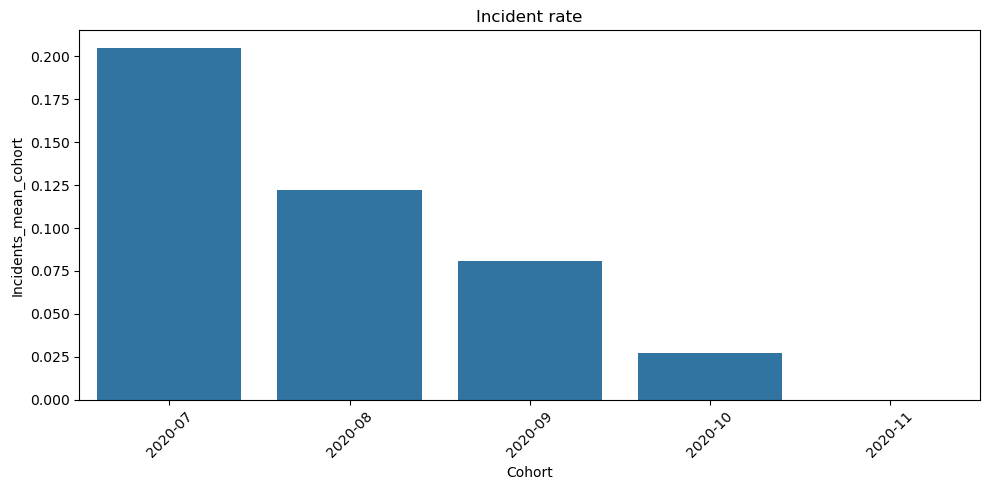

In [94]:

final_df_1['incidents'] = (final_df_1['type'] == 'incident').astype(int)
incident_rate = final_df_1.groupby('cohort')['incidents'].mean().reset_index(name="Incidents_mean_cohorts")
incident_rate
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 5))
sns.barplot(data=incident_rate, x="cohort", y="Incidents_mean_cohorts")
plt.title("Incident rate")
plt.ylabel("Incidents_mean_cohort")
plt.xlabel("Cohort")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

